# Improving RAG with Reranking, Chunking, and Conversational Memory
**Dataset:** `ccdv/arxiv-summarization` (`document` config, train split, first 100 documents)
**Vector DB:** ChromaDB · **Embedder:** `all-MiniLM-L6-v2` · **Reranker:** `cross-encoder/ms-marco-MiniLM-L-6-v2`


## Cell 1 — Session bootstrap (guide §1)
Edit `USERNAME`, `REPO`, and **`HW`** before running.

In [1]:
from google.colab import userdata
import sys, os, subprocess  # subprocess imported explicitly — avoids the NameError bug

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw10"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap
import importlib
importlib.reload(colab_bootstrap)   # force fresh reload, avoid stale cached module
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw10:=== Session started for hw10 ===


Working directory: /content/data266-5937/hw10
[main 199b421] hw10: session start
 2 files changed, 1 insertion(+)
 create mode 100644 hw10/RUN_LOG.txt
 


## Cell 2 — Personal parameters (guide §2)
Only `SEED` is used in this assignment (all random seeds).

In [2]:
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

INFO:/content/data266-5937/hw10:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


## Cell 3 — Install libraries, imports, seeds

In [3]:
!pip -q install chromadb sentence-transformers datasets tabulate

import re, json, random, time
from itertools import islice
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# chart colours (fixed order, one per configuration)
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
pd.set_option("display.max_colwidth", 120)

logger.info(f"Installed chromadb / sentence-transformers / datasets; device={device}")
git_commit_push(REPO_PATH, f"{HW}: environment setup")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 require

INFO:/content/data266-5937/hw10:Installed chromadb / sentence-transformers / datasets; device=cuda


device: cuda
[main 765858a] hw10: environment setup
 1 file changed, 2 insertions(+)
 


## Cell 4 — Load the first 100 documents (`document` config, train split)


In [4]:
from datasets import load_dataset

N_DOCS = 100

def load_first_n(n=N_DOCS):
    try:
        ds = load_dataset("ccdv/arxiv-summarization", "document", split="train", streaming=True)
        return list(islice(ds, n)), "hub: ccdv/arxiv-summarization [document/train]"
    except Exception as e:
        print("Standard load failed ->", repr(e)[:300])
    base = "hf://datasets/ccdv/arxiv-summarization@refs/convert/parquet/document"
    for pattern in [f"{base}/train/*.parquet", f"{base}/*train*.parquet"]:
        try:
            ds = load_dataset("parquet", data_files={"train": pattern}, split="train", streaming=True)
            return list(islice(ds, n)), f"parquet fallback: {pattern}"
        except Exception as e:
            print("Fallback failed ->", pattern, repr(e)[:200])
    raise RuntimeError("Could not load ccdv/arxiv-summarization")

rows, source = load_first_n()
print("Loaded", len(rows), "rows from", source, "| fields:", list(rows[0].keys()))

docs = [{"doc_id": i, "article": r.get("article", "") or "", "abstract": r.get("abstract", "") or ""}
        for i, r in enumerate(rows)]

overview = pd.DataFrame({
    "doc_id": [d["doc_id"] for d in docs],
    "article_words": [len(d["article"].split()) for d in docs],
    "abstract_start": [d["abstract"][:150].replace("\n", " ") for d in docs],
})
print(overview["article_words"].describe())
overview.to_csv(f"{HW_PATH}/doc_overview.csv", index=False)
display(overview.head(15))

logger.info(f"Loaded {len(docs)} docs ({source}); mean article words={overview.article_words.mean():.0f}")
git_commit_push(REPO_PATH, f"{HW}: load first 100 arxiv documents + doc_overview.csv")

README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

Loaded 100 rows from hub: ccdv/arxiv-summarization [document/train] | fields: ['article', 'abstract']
count      100.000000
mean      6516.530000
std       5442.174345
min        604.000000
25%       3265.000000
50%       4847.000000
75%       8004.000000
max      33095.000000
Name: article_words, dtype: float64


,doc_id,article_words,abstract_start
0,0,4467,additive models play an important role in semiparametric statistics . this paper gives learning rates for regulari...
1,1,3223,"we have studied the leptonic decay @xmath0 , via the decay channel @xmath1 , using a sample of tagged @xmath2 decays..."
2,2,5292,"in 84 , 258 ( 2000 ) , mateos conjectured that current reversal in a classical deterministic ratchet is associated w..."
3,3,3714,the effect of a random phase diffuser on fluctuations of laser light ( scintillations ) is studied . not only spat...
4,4,9235,"with a special intention of clarifying the underlying spin contents of the nucleon , we investigate the generalized ..."
5,5,6725,we improve the currently known thresholds for basisness of the family of periodically dilated @xmath0-sine functions...
6,6,2805,we report on strong enhancement of mid - infrared second harmonic generation ( shg ) from sic nanopillars due to the...
7,7,3386,synaptic memory is considered to be the main element responsible for learning and cognition in humans . although t...
8,8,1843,"this paper investigates , using prior shape models and the concept of ball scale ( b - scale ) , ways of automatical..."
9,9,5670,long time coverage and high radial velocity precision have allowed for the discovery of additional objects in known ...


INFO:/content/data266-5937/hw10:Loaded 100 docs (hub: ccdv/arxiv-summarization [document/train]); mean article words=6517


[main 8606d74] hw10: load first 100 arxiv documents + doc_overview.csv
 2 files changed, 102 insertions(+)
 create mode 100644 hw10/doc_overview.csv
 


## Cell 5 — Preprocessing
The arXiv text is already lower-cased and tokenised, with placeholders such as `@xmath12` (math) and `@xcite` (citations).
We remove those placeholders, empty brackets and figure refs, re-attach punctuation (`word .` → `word.`) so sentence splitting works,
and keep `\n` as the paragraph/section boundary.

In [5]:
def clean_text(t: str) -> str:
    t = re.sub(r"@xmath\d+", " ", t)                       # math placeholders
    t = re.sub(r"@x?cite\w*", " ", t)                        # citation placeholders
    t = re.sub(r"\[\s*(fig|tab|eq|sec)[^\]]{0,20}\]", " ", t, flags=re.I)  # [ fig1 ] style refs
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\(\s*[,;]?\s*\)", " ", t)                 # empty ( ) left after removing math
    t = re.sub(r"\s+([.,;:!?)\]])", r"\1", t)               # 'word .' -> 'word.'
    t = re.sub(r"([(\[])\s+", r"\1", t)                    # '( word' -> '(word'
    t = re.sub(r"(,\s*){2,}", ", ", t)
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\s*\n\s*", "\n", t)                        # normalise paragraph breaks
    return t.strip()

for d in docs:
    d["clean"] = clean_text(d["article"])

docs = [d for d in docs if len(d["clean"].split()) > 50]   # drop empty/near-empty articles
print("Docs kept after cleaning:", len(docs))
print("RAW   :", docs[0]["article"][:400].replace("\n", " | "))
print("CLEAN :", docs[0]["clean"][:400].replace("\n", " | "))

logger.info(f"Preprocessed {len(docs)} docs (removed @xmath/@xcite placeholders, fixed punctuation spacing)")
git_commit_push(REPO_PATH, f"{HW}: preprocessing")

INFO:/content/data266-5937/hw10:Preprocessed 100 docs (removed @xmath/@xcite placeholders, fixed punctuation spacing)


Docs kept after cleaning: 100
RAW   : additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general
CLEAN : additive models provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models. it is well - known that good estimators in additive models are in general less pro
[main 4852bcf] hw10: preprocessing
 1 file changed, 1 insertion(+)
 


## Cell 6 — Two chunking strategies
Both use the **same size budget (≤150 words)** so the comparison isolates *how* text is cut, not *how much*.

| | Strategy 1: `fixed` | Strategy 2: `sentence` |
|---|---|---|
| Unit | words | sentences, grouped inside paragraphs/sections |
| Size | exactly 150 words | up to 150 words |
| Overlap | 30 words | 1 sentence |
| Boundaries | ignores sentences & sections (can cut mid-sentence) | never cuts a sentence; closes a chunk at a section break once it has ≥60 words |

150 words keeps most chunks under the embedder's 256-token limit (checked in Cell 7).

In [6]:
CHUNK_WORDS, OVERLAP_WORDS, MIN_WORDS = 150, 30, 60
STRATEGIES = ["fixed", "sentence"]

def chunk_fixed(text, size=CHUNK_WORDS, overlap=OVERLAP_WORDS):
    words = text.split()
    step = size - overlap
    out = []
    for start in range(0, len(words), step):
        out.append(" ".join(words[start:start + size]))
        if start + size >= len(words):
            break
    return out

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")

def split_sentences(paragraph):
    sents = [s.strip() for s in SENT_SPLIT.split(paragraph) if s.strip()]
    merged = []
    for s in sents:   # glue tiny fragments ('et al.', 'fig.') back onto the previous sentence
        if merged and len(s.split()) < 6:
            merged[-1] += " " + s
        else:
            merged.append(s)
    return merged

def chunk_sentences(text, max_words=CHUNK_WORDS, min_words=MIN_WORDS, overlap_sents=1):
    nw = lambda sents: sum(len(s.split()) for s in sents)
    chunks, cur = [], []
    for para in [p for p in text.split("\n") if p.strip()]:
        for s in split_sentences(para):
            w = len(s.split())
            if w > max_words:                      # run-on 'sentence' (lost punctuation) -> hard split
                if cur: chunks.append(" ".join(cur)); cur = []
                chunks.extend(chunk_fixed(s, max_words, 0))
                continue
            if cur and nw(cur) + w > max_words:    # chunk full -> emit, keep last sentence as overlap
                chunks.append(" ".join(cur))
                cur = cur[-overlap_sents:] if overlap_sents else []
                if nw(cur) + w > max_words: cur = []
            cur.append(s)
        if nw(cur) >= min_words:                   # section/paragraph boundary -> close the chunk
            chunks.append(" ".join(cur)); cur = []
    if cur:
        chunks.append(" ".join(cur))
    return chunks

CHUNKERS = {"fixed": chunk_fixed, "sentence": chunk_sentences}
chunks = {}
for name, fn in CHUNKERS.items():
    recs = []
    for d in docs:
        for j, txt in enumerate(fn(d["clean"])):
            recs.append({"chunk_id": f"{name}-d{d['doc_id']}-c{j}", "strategy": name,
                         "doc_id": d["doc_id"], "chunk_idx": j, "text": txt, "n_words": len(txt.split())})
    chunks[name] = recs

chunk_stats = pd.DataFrame([{
    "strategy": n, "n_chunks": len(c),
    "mean_words": np.mean([x["n_words"] for x in c]), "median_words": np.median([x["n_words"] for x in c]),
    "min_words": min(x["n_words"] for x in c), "max_words": max(x["n_words"] for x in c),
    "pct_end_mid_sentence": 100 * np.mean([not x["text"].rstrip().endswith((".", "!", "?")) for x in c]),
} for n, c in chunks.items()]).round(1)
display(chunk_stats)

for n in STRATEGIES:
    print(f"\n--- {n}: doc 0, chunk 1 ---\n", chunks[n][1]["text"][:500])

logger.info("Chunking done: " + "; ".join(f"{r.strategy}={r.n_chunks} chunks (mean {r.mean_words} words)"
                                          for r in chunk_stats.itertuples()))
git_commit_push(REPO_PATH, f"{HW}: implement fixed-window and sentence-aware chunking")

,strategy,n_chunks,mean_words,median_words,min_words,max_words,pct_end_mid_sentence
0,fixed,4351,148.6,150.0,35,150,92.3
1,sentence,4644,133.6,139.0,4,150,1.9


INFO:/content/data266-5937/hw10:Chunking done: fixed=4351 chunks (mean 148.6 words); sentence=4644 chunks (mean 133.6 words)



--- fixed: doc 0, chunk 1 ---
 on sparsity and when the classical least squares loss function is used, see e.g., and the references therein. of course, the least squares loss function is differentiable and has many nice mathematical properties, but it is only locally lipschitz continuous and therefore regularized kernel based methods based on this loss function typically suffer on bad statistical robustness properties, even if the kernel is bounded. this is in sharp contrast to kernel methods based on a lipschitz continuous l

--- sentence: doc 0, chunk 1 ---
 in the last years many interesting results on learning rates of regularized kernel based models for additive models have been published when the focus is on sparsity and when the classical least squares loss function is used, see e.g., and the references therein. of course, the least squares loss function is differentiable and has many nice mathematical properties, but it is only locally lipschitz continuous and therefore regula

## Cell 7 — Chunk length distribution figure

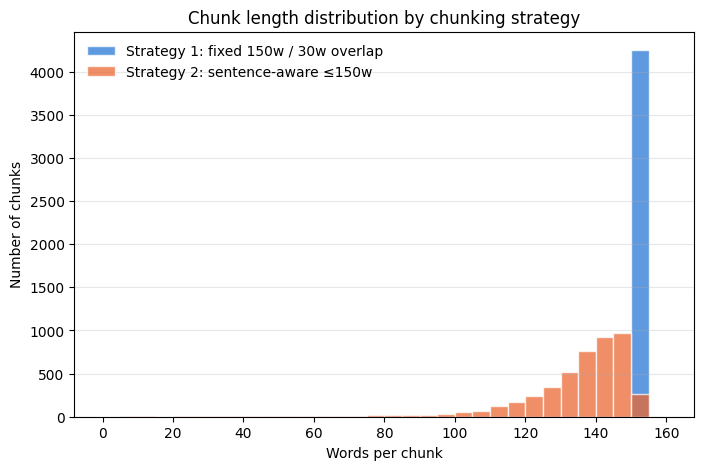

INFO:/content/data266-5937/hw10:Saved chunk_length_distribution.png


55203 bytes
[main 63d6324] hw10: chunk length distribution figure
 2 files changed, 1 insertion(+)
 create mode 100644 hw10/chunk_length_distribution.png
 


In [7]:
plt.figure(figsize=(8, 5))
bins = np.arange(0, CHUNK_WORDS + 11, 5)
plt.hist([x["n_words"] for x in chunks["fixed"]], bins=bins, color=C_BLUE, alpha=0.75,
         label="Strategy 1: fixed 150w / 30w overlap", edgecolor="white", linewidth=1)
plt.hist([x["n_words"] for x in chunks["sentence"]], bins=bins, color=C_ORANGE, alpha=0.75,
         label="Strategy 2: sentence-aware ≤150w", edgecolor="white", linewidth=1)
plt.xlabel("Words per chunk"); plt.ylabel("Number of chunks")
plt.title("Chunk length distribution by chunking strategy")
plt.legend(frameon=False); plt.grid(axis="y", alpha=0.3)
plt.savefig(f"{HW_PATH}/chunk_length_distribution.png", bbox_inches="tight", dpi=150)  # SAVE BEFORE show()
plt.show(); plt.close()
print(os.path.getsize(f"{HW_PATH}/chunk_length_distribution.png"), "bytes")

logger.info("Saved chunk_length_distribution.png")
git_commit_push(REPO_PATH, f"{HW}: chunk length distribution figure")

## Cell 8 — Embed both chunk sets

In [8]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMBED_MODEL, device=device)
print("max_seq_length:", embedder.max_seq_length)

def embed(texts, bs=128, progress=False):
    return embedder.encode(texts, batch_size=bs, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=progress)

embeddings = {}
for n in STRATEGIES:
    t0 = time.time()
    embeddings[n] = embed([c["text"] for c in chunks[n]], progress=True)
    tok_lens = [len(embedder.tokenizer(c["text"])["input_ids"]) for c in chunks[n]]
    trunc = 100 * np.mean(np.array(tok_lens) > embedder.max_seq_length)
    print(f"{n}: {embeddings[n].shape}, {time.time()-t0:.1f}s, {trunc:.1f}% of chunks exceed {embedder.max_seq_length} tokens")

logger.info(f"Embedded chunks with {EMBED_MODEL}: " + ", ".join(f"{n}={embeddings[n].shape}" for n in STRATEGIES))
git_commit_push(REPO_PATH, f"{HW}: embed chunks with all-MiniLM-L6-v2")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (10 outputs left out)

fixed: (4351, 384), 16.2s, 15.1% of chunks exceed 256 tokens


Batches:   0%|          | 0/37 [00:00<?, ?it/s]

INFO:/content/data266-5937/hw10:Embedded chunks with sentence-transformers/all-MiniLM-L6-v2: fixed=(4351, 384), sentence=(4644, 384)


sentence: (4644, 384), 16.0s, 11.1% of chunks exceed 256 tokens
[main 4a83276] hw10: embed chunks with all-MiniLM-L6-v2
 1 file changed, 1 insertion(+)
 


## Cell 9 — Index in ChromaDB (one collection per chunking strategy)
The DB lives in `/content/chroma_db`, **outside the repo** on purpose (binary files don't belong in git).

In [9]:
import chromadb

CHROMA_PATH = "/content/chroma_db"
client = chromadb.PersistentClient(path=CHROMA_PATH)
collections = {}

for n in STRATEGIES:
    cname = f"arxiv_{n}"
    try:
        client.delete_collection(cname)
    except Exception:
        pass
    try:
        col = client.create_collection(name=cname, metadata={"hnsw:space": "cosine"})
    except Exception:
        col = client.create_collection(name=cname)  # vectors are L2-normalised, so ranking is the same
    B = 1000                                      # Chroma has a max batch size; add in batches
    for i in range(0, len(chunks[n]), B):
        batch = chunks[n][i:i + B]
        col.add(ids=[c["chunk_id"] for c in batch],
                embeddings=embeddings[n][i:i + B].tolist(),
                documents=[c["text"] for c in batch],
                metadatas=[{"doc_id": c["doc_id"], "chunk_idx": c["chunk_idx"],
                            "n_words": c["n_words"], "strategy": n} for c in batch])
    collections[n] = col
    print(cname, "->", col.count(), "vectors")

logger.info("Indexed in ChromaDB: " + ", ".join(f"arxiv_{n}={collections[n].count()}" for n in STRATEGIES))
git_commit_push(REPO_PATH, f"{HW}: index both chunk sets in ChromaDB")

arxiv_fixed -> 4351 vectors


INFO:/content/data266-5937/hw10:Indexed in ChromaDB: arxiv_fixed=4351, arxiv_sentence=4644


arxiv_sentence -> 4644 vectors
[main 01693b4] hw10: index both chunk sets in ChromaDB
 1 file changed, 1 insertion(+)
 


## Cell 10 — Retrieval functions (dense only vs. dense + cross-encoder reranking)
*Without reranking*: top-K by embedding similarity.
*With reranking*: take the top 30 dense candidates, score each `(query, chunk)` pair jointly with a cross-encoder, re-sort, keep top-K.

In [10]:
from sentence_transformers import CrossEncoder

TOP_K_MAX = 10          # we evaluate @5 and @10
N_CANDIDATES = 30       # candidate pool handed to the reranker
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
reranker = CrossEncoder(RERANK_MODEL, device=device)

def retrieve(query, strategy, k=TOP_K_MAX):
    q = embed([query])[0]
    res = collections[strategy].query(query_embeddings=[q.tolist()], n_results=k,
                                      include=["documents", "metadatas", "distances"])
    return [{"rank": r, "chunk_id": cid, "doc_id": m["doc_id"], "text": doc, "distance": float(dist)}
            for r, (cid, doc, m, dist) in enumerate(zip(res["ids"][0], res["documents"][0],
                                                       res["metadatas"][0], res["distances"][0]), 1)]

def retrieve_rerank(query, strategy, k=TOP_K_MAX, n_candidates=N_CANDIDATES):
    cands = retrieve(query, strategy, k=n_candidates)
    scores = reranker.predict([(query, c["text"]) for c in cands])
    for c, s in zip(cands, scores):
        c["dense_rank"], c["rerank_score"] = c["rank"], float(s)
    cands.sort(key=lambda c: -c["rerank_score"])
    for i, c in enumerate(cands, 1):
        c["rank"] = i
    return cands[:k]

def search(query, strategy, rerank=False, k=TOP_K_MAX):
    return retrieve_rerank(query, strategy, k) if rerank else retrieve(query, strategy, k)

print(retrieve("dark matter", "fixed", k=2)[0]["text"][:200])
logger.info(f"Retrieval ready (dense top-{TOP_K_MAX}; rerank {N_CANDIDATES}->{TOP_K_MAX} with {RERANK_MODEL})")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

INFO:/content/data266-5937/hw10:Retrieval ready (dense top-10; rerank 30->10 with cross-encoder/ms-marco-MiniLM-L-6-v2)


of the coupling for light (for the dependence of coupling on, see sec. this figure also indicates that for the nmssm and the nmssm, is upper bounded by. for the nmssm, this is because large can suppre


## Cell 11 — Queries and the relevance rubric
**Relevance definition (manual rubric).** For each query I wrote, by hand, a *core* term list (the topic) and an *aspect* term list (what the question asks about).
A chunk counts as **relevant = useful for answering** if it mentions the topic **and** at least `min_aspect` aspect terms. Terms are prefix matches (`detect` matches *detection*).
This makes judgments consistent across all 8 configurations and lets us compute **Recall@K** (the denominator = all relevant chunks in that collection).
Cell 14 lets you override any individual judgment after reading the chunk.

Because I can't know in advance which topics the first 100 papers cover, the cell scores a pool of candidate questions against the corpus and
**keeps the 3 best-covered as standalone queries**, plus one topic for the **2-turn conversation**.
Set `MANUAL_QUERY_IDS` / `MANUAL_CONV_ID` to pick your own instead.

In [11]:
TOPIC_POOL = [
 dict(id="dark_matter", query="How is dark matter detected or constrained by observations?",
      core=["dark matter"], aspect=["detect", "annihilat", "constrain", "cross section", "signal", "wimp", "experiment"]),
 dict(id="black_hole", query="How is the mass of a black hole measured or estimated?",
      core=["black hole"], aspect=["mass", "estimat", "measur", "accretion", "luminosit", "velocity dispersion", "reverberation"]),
 dict(id="neutron_star", query="What determines the mass and radius of neutron stars?",
      core=["neutron star", "pulsar"], aspect=["mass", "radius", "radii", "equation of state", "density", "nuclear matter"]),
 dict(id="star_formation", query="What drives star formation in galaxies?",
      core=["star formation", "star-forming"], aspect=["gas", "molecular", "rate", "feedback", "galax", "density"]),
 dict(id="superconductivity", query="What is the pairing mechanism in superconductors?",
      core=["superconduct"], aspect=["pairing", "gap", "cooper", "phonon", "critical temperature", "symmetry", "order parameter"]),
 dict(id="entanglement", query="How is quantum entanglement quantified and measured?",
      core=["entangle"], aspect=["measure", "quantif", "concurrence", "entropy", "qubit", "bell", "witness"]),
 dict(id="graphene", query="What are the electronic properties of graphene?",
      core=["graphene"], aspect=["electron", "band", "dirac", "conductiv", "transport", "fermi"]),
 dict(id="phase_transition", query="How are phase transitions and critical behaviour characterized?",
      core=["phase transition", "critical point"], aspect=["critical exponent", "order parameter", "scaling", "universality", "critical temperature", "first order", "second order"]),
 dict(id="monte_carlo", query="How are Monte Carlo simulations performed?",
      core=["monte carlo"], aspect=["simulat", "sampl", "algorithm", "metropolis", "configuration", "statistical error", "event"]),
 dict(id="neutrino", query="How are neutrino masses and oscillations measured?",
      core=["neutrino"], aspect=["oscillat", "mass", "mixing", "detector", "flux", "solar"]),
 dict(id="cmb", query="What do cosmic microwave background measurements tell us about cosmological parameters?",
      core=["cosmic microwave background", "cmb"], aspect=["anisotrop", "polariz", "cosmolog", "power spectrum", "parameter", "temperature fluctuation"]),
 dict(id="qcd", query="What does QCD predict about quarks and hadron properties?",
      core=["qcd", "quark"], aspect=["lattice", "hadron", "gluon", "coupling", "chiral", "meson"]),
 dict(id="neural_net", query="How are neural networks trained for classification?",
      core=["neural network", "machine learning", "deep learning"], aspect=["train", "layer", "classif", "learn", "weight", "loss"]),
 dict(id="grb", query="What powers gamma-ray bursts and their afterglows?",
      core=["gamma-ray burst", "gamma ray burst", "grb"], aspect=["afterglow", "jet", "emission", "progenitor", "redshift", "energy"]),
 dict(id="galaxy_cluster", query="How are the masses of galaxy clusters measured?",
      core=["galaxy cluster", "cluster of galaxies", "clusters of galaxies"], aspect=["mass", "lensing", "x-ray", "temperature", "sunyaev", "velocit"]),
 dict(id="exoplanet", query="How are extrasolar planets detected?",
      core=["exoplanet", "extrasolar planet", "planet"], aspect=["transit", "radial velocit", "detect", "orbit", "host star", "microlensing"]),
 dict(id="random_graph", query="What properties of random graphs and networks are proved?",
      core=["random graph", "graphs?\\b", "complex network"], aspect=["vertex", "vertices", "edge", "degree", "bound", "theorem"]),
 dict(id="magnetism", query="What are the magnetic properties and ordering of spin systems?",
      core=["antiferromagnet", "ferromagnet", "spin chain", "ising", "heisenberg"], aspect=["magnetiz", "exchange", "order", "susceptib", "frustrat", "ground state"]),
 dict(id="solar", query="What causes solar flares and heating of the corona?",
      core=["solar", "corona"], aspect=["flare", "magnetic", "coronal", "reconnection", "heating", "plasma"]),
 dict(id="protein", query="How do proteins fold and bind?",
      core=["protein"], aspect=["fold", "structure", "binding", "amino acid", "molecular dynamics"]),
]
for t in TOPIC_POOL:
    t.setdefault("min_aspect", 2)

# Turn 2 of the conversation: deliberately does NOT name the topic -> only answerable with turn-1 context
FOLLOWUP_QUERY = "What are the main sources of uncertainty or error in those measurements?"
FOLLOWUP_ASPECT = ["uncertaint", "systematic", "error", "bias", "accuracy", "precision", "limitation"]

def _hit(text, term):
    return re.search(r"\b" + (term if "\\" in term else re.escape(term)), text) is not None

def is_relevant(text, rubric):
    t = text.lower()
    return (any(_hit(t, c) for c in rubric["core"])
            and sum(_hit(t, a) for a in rubric["aspect"]) >= rubric["min_aspect"])

def followup_rubric(topic):
    return {"core": topic["core"], "aspect": FOLLOWUP_ASPECT, "min_aspect": 1}

coverage = []
for t in TOPIC_POOL:
    row = {"topic": t["id"], "query": t["query"]}
    for n in STRATEGIES:
        row[f"rel_{n}"] = sum(is_relevant(c["text"], t) for c in chunks[n])
        row[f"rel_docs_{n}"] = len({c["doc_id"] for c in chunks[n] if is_relevant(c["text"], t)})
    row["followup_rel_fixed"] = sum(is_relevant(c["text"], followup_rubric(t)) for c in chunks["fixed"])
    coverage.append(row)
coverage = pd.DataFrame(coverage).sort_values("rel_fixed", ascending=False).reset_index(drop=True)
display(coverage)
coverage.to_csv(f"{HW_PATH}/query_coverage.csv", index=False)

MANUAL_QUERY_IDS = None   # e.g. ["dark_matter", "graphene", "neutrino"]
MANUAL_CONV_ID = None     # e.g. "neutrino"

topic_by_id = {t["id"]: t for t in TOPIC_POOL}
query_ids = MANUAL_QUERY_IDS or coverage.topic.head(3).tolist()
rest = coverage[~coverage.topic.isin(query_ids)].sort_values("followup_rel_fixed", ascending=False)
conv_id = MANUAL_CONV_ID or rest.topic.iloc[0]

QUERIES = [{"qid": f"Q{i+1}", **topic_by_id[tid]} for i, tid in enumerate(query_ids)]
CONV_TOPIC = topic_by_id[conv_id]
for q in QUERIES:
    print(f"{q['qid']} [{q['id']}]: {q['query']}")
print(f"Conversation topic [{conv_id}] -> turn 1: {CONV_TOPIC['query']} | turn 2: {FOLLOWUP_QUERY}")
low = coverage[coverage.topic.isin(query_ids + [conv_id]) & (coverage.rel_fixed < 5)]
if len(low): print("WARNING: few relevant chunks for", low.topic.tolist(), "- consider MANUAL_QUERY_IDS")

logger.info(f"Queries selected: {[(q['qid'], q['id']) for q in QUERIES]}; conversation topic={conv_id}")
git_commit_push(REPO_PATH, f"{HW}: define queries, relevance rubric, query_coverage.csv")

,topic,query,rel_fixed,rel_docs_fixed,rel_sentence,rel_docs_sentence,followup_rel_fixed
0,qcd,What does QCD predict about quarks and hadron properties?,32,5,25,5,22
1,cmb,What do cosmic microwave background measurements tell us about cosmological parameters?,18,2,21,2,11
2,magnetism,What are the magnetic properties and ordering of spin systems?,18,4,16,4,1
3,star_formation,What drives star formation in galaxies?,15,4,16,4,2
4,solar,What causes solar flares and heating of the corona?,15,3,16,4,6
5,grb,What powers gamma-ray bursts and their afterglows?,13,1,15,1,15
6,exoplanet,How are extrasolar planets detected?,11,1,12,1,17
7,random_graph,What properties of random graphs and networks are proved?,9,5,11,5,3
8,galaxy_cluster,How are the masses of galaxy clusters measured?,8,1,6,1,1
9,protein,How do proteins fold and bind?,7,1,4,1,5


INFO:/content/data266-5937/hw10:Queries selected: [('Q1', 'qcd'), ('Q2', 'cmb'), ('Q3', 'magnetism')]; conversation topic=exoplanet


Q1 [qcd]: What does QCD predict about quarks and hadron properties?
Q2 [cmb]: What do cosmic microwave background measurements tell us about cosmological parameters?
Q3 [magnetism]: What are the magnetic properties and ordering of spin systems?
Conversation topic [exoplanet] -> turn 1: How are extrasolar planets detected? | turn 2: What are the main sources of uncertainty or error in those measurements?
[main d282742] hw10: define queries, relevance rubric, query_coverage.csv
 2 files changed, 23 insertions(+)
 create mode 100644 hw10/query_coverage.csv
 


## Cell 12 — Sample queries **without** reranking (both chunking strategies)

In [12]:
def show(results, rubric, k=5, title=""):
    print(f"\n=== {title} ===")
    for r in results[:k]:
        lab = "REL" if is_relevant(r["text"], rubric) else " - "
        extra = f" (dense rank {r['dense_rank']}, ce={r['rerank_score']:.2f})" if "rerank_score" in r else f" (dist={r['distance']:.3f})"
        print(f"{r['rank']:>2}. [{lab}] doc {r['doc_id']:>3} {r['chunk_id']}{extra}\n    {r['text'][:220]}...")

RUNS = {}   # (qid, strategy, rerank) -> ranked results
for q in QUERIES:
    for n in STRATEGIES:
        RUNS[(q["qid"], n, False)] = search(q["query"], n, rerank=False)
        show(RUNS[(q["qid"], n, False)], q, title=f"{q['qid']} | {n} | NO rerank | {q['query']}")

logger.info("Ran dense retrieval (no reranking) for all queries x both strategies")
git_commit_push(REPO_PATH, f"{HW}: baseline retrieval without reranking")

INFO:/content/data266-5937/hw10:Ran dense retrieval (no reranking) for all queries x both strategies



=== Q1 | fixed | NO rerank | What does QCD predict about quarks and hadron properties? ===
 1. [ - ] doc   4 fixed-d4-c37 (dist=0.387)
    spin structure of the nucleon. at zero momentum transfer, the relations between the generalized dirac and pauli form factors and the generalized sachs - type form factors are simplified to become and and as functions of ...
 2. [REL] doc   4 fixed-d4-c56 (dist=0.419)
    the prediction of the cqsm for the total quark angular momentum is not extremely far from the corresponding lattice prediction at the same renormalization scale. the cause of discrepancy can therefore be traced back to t...
 3. [ - ] doc   4 fixed-d4-c6 (dist=0.426)
    shown to be essential to understand the famous nmc measurement, which revealed the dominance of the -quark over the -quark inside the proton, . then, it would be interesting to see what predictions the cqsm would give fo...
 4. [ - ] doc   4 fixed-d4-c53 (dist=0.432)
    it is a widely accepted fact that this flavor

## Cell 13 — Same queries **with** cross-encoder reranking

In [13]:
for q in QUERIES:
    for n in STRATEGIES:
        RUNS[(q["qid"], n, True)] = search(q["query"], n, rerank=True)
        show(RUNS[(q["qid"], n, True)], q, title=f"{q['qid']} | {n} | WITH rerank | {q['query']}")

logger.info("Ran retrieval with cross-encoder reranking for all queries x both strategies")
git_commit_push(REPO_PATH, f"{HW}: retrieval with reranking")


=== Q1 | fixed | WITH rerank | What does QCD predict about quarks and hadron properties? ===
 1. [REL] doc   4 fixed-d4-c38 (dense rank 10, ce=4.18)
    difference between the predictions of the cqsm and of the lattice qcd. the lattice qcd predicts that which means that only about of the total nucleon momentum is carried by the quark fields, while the rest is borne by th...
 2. [REL] doc   4 fixed-d4-c56 (dense rank 2, ce=3.81)
    the prediction of the cqsm for the total quark angular momentum is not extremely far from the corresponding lattice prediction at the same renormalization scale. the cause of discrepancy can therefore be traced back to t...
 3. [ - ] doc   4 fixed-d4-c55 (dense rank 7, ce=3.02)
    the underlying spin contents of the nucleon through the analysis of the gravitoelectric and gravitomagnetic form factors of the nucleon, by taking care of the pion mass despondencies as well as of the scale dependencies ...
 4. [REL] doc  68 fixed-d68-c30 (dense rank 24, ce=2.65)

INFO:/content/data266-5937/hw10:Ran retrieval with cross-encoder reranking for all queries x both strategies



=== Q3 | fixed | WITH rerank | What are the magnetic properties and ordering of spin systems? ===
 1. [REL] doc  80 fixed-d80-c4 (dense rank 2, ce=3.52)
    - ferromagnetic ordering, or the singlet state, (i.e. two neighboring spins are anti - parallel) is preferred over the ferromagnetic ordering, or triplet state (two spins are parallel). we will assume that the tendency t...
 2. [REL] doc  50 fixed-d50-c0 (dense rank 5, ce=3.37)
    the study of the phase transition of frustrated spin systems on two - dimensional (2d) lattices is a central problem in modern condensed mater physics. a competition of exchange interaction can lead to frustration, where...
 3. [REL] doc  80 fixed-d80-c5 (dense rank 7, ce=2.50)
    spin configuration shown in fig. we will call `` upspin '' the spin orientation directed along the magnetic field and `` downspin '' the opposite orientation. we encode logic 1 in the upspin state. furthermore, we will c...
 4. [REL] doc  50 fixed-d50-c1 (dense rank 1, ce=2.1

In [14]:
MANUAL_LABELS = {
    # ("Q1", "fixed-d12-c7"): 0,     # e.g. mentions the terms but doesn't actually help answer
    # ("Q2", "sentence-d40-c3"): 1,
}

def relevant_set(qid, rubric, strategy):
    rel = {c["chunk_id"] for c in chunks[strategy] if is_relevant(c["text"], rubric)}
    for (q, cid), lab in MANUAL_LABELS.items():
        if q == qid and cid.startswith(strategy + "-"):
            (rel.add if lab else rel.discard)(cid)
    return rel

print("Relevant chunks per query/strategy:")
for q in QUERIES:
    print(q["qid"], {n: len(relevant_set(q["qid"], q, n)) for n in STRATEGIES})
logger.info(f"Manual label overrides: {len(MANUAL_LABELS)}")

Relevant chunks per query/strategy:
Q1 {'fixed': 32, 'sentence': 25}
Q2 {'fixed': 18, 'sentence': 21}


INFO:/content/data266-5937/hw10:Manual label overrides: 0


Q3 {'fixed': 18, 'sentence': 16}


## Cell 15 — Evaluate: Precision@K, Recall@K, MRR
* **P@K** = relevant in top-K / K  * **R@K** = relevant in top-K / all relevant chunks in that collection  * **MRR** = 1 / rank of first relevant (0 if none in top-10)

In [15]:
EVAL_KS = [5, 10]

def evaluate(results, rel):
    ids = [r["chunk_id"] for r in results]
    out = {}
    for k in EVAL_KS:
        hits = sum(cid in rel for cid in ids[:k])
        out[f"P@{k}"] = hits / k
        out[f"R@{k}"] = hits / len(rel) if rel else 0.0
    first = next((i for i, cid in enumerate(ids, 1) if cid in rel), None)
    out["MRR"] = 1 / first if first else 0.0
    return out

rows = []
for q in QUERIES:
    for n in STRATEGIES:
        rel = relevant_set(q["qid"], q, n)
        for rr in [False, True]:
            rows.append({"query": q["qid"], "strategy": n, "reranking": "with" if rr else "without",
                         "n_relevant": len(rel), **evaluate(RUNS[(q["qid"], n, rr)], rel)})
eval_df = pd.DataFrame(rows)
eval_df.to_csv(f"{HW_PATH}/eval_per_query.csv", index=False)
display(eval_df.round(3))

METRIC_COLS = ["P@5", "R@5", "P@10", "R@10", "MRR"]
summary = eval_df.groupby(["strategy", "reranking"])[METRIC_COLS].mean().round(3).reset_index()
summary["config"] = summary.strategy + " / " + summary.reranking + " rerank"
summary.to_csv(f"{HW_PATH}/eval_summary.csv", index=False)
display(summary)

# save every retrieved list for the record
qmap = {q["qid"]: q for q in QUERIES}
pd.DataFrame([{"query": k[0], "strategy": k[1], "rerank": k[2], "rank": r["rank"], "chunk_id": r["chunk_id"],
               "doc_id": r["doc_id"], "relevant": r["chunk_id"] in relevant_set(k[0], qmap[k[0]], k[1]),
               "text": r["text"][:300]} for k, res in RUNS.items() for r in res]
            ).to_csv(f"{HW_PATH}/retrieval_results.csv", index=False)

logger.info("Evaluation (no memory): " + "; ".join(f"{r['config']}: P@5={r['P@5']:.2f} MRR={r['MRR']:.2f}" for _, r in summary.iterrows()))
git_commit_push(REPO_PATH, f"{HW}: evaluate P@K/R@K/MRR, eval_per_query.csv + eval_summary.csv")

,query,strategy,reranking,n_relevant,P@5,R@5,P@10,R@10,MRR
0,Q1,fixed,without,32,0.4,0.062,0.6,0.188,0.5
1,Q1,fixed,with,32,0.8,0.125,0.8,0.250,1.0
2,Q1,sentence,without,25,0.8,0.160,0.8,0.320,1.0
3,Q1,sentence,with,25,0.8,0.160,0.7,0.280,1.0
4,Q2,fixed,without,18,0.2,0.056,0.1,0.056,0.5
5,Q2,fixed,with,18,0.2,0.056,0.1,0.056,0.2
6,Q2,sentence,without,21,0.4,0.095,0.4,0.190,1.0
7,Q2,sentence,with,21,0.2,0.048,0.2,0.095,0.2
8,Q3,fixed,without,18,0.8,0.222,0.5,0.278,1.0
9,Q3,fixed,with,18,1.0,0.278,0.6,0.333,1.0


,strategy,reranking,P@5,R@5,P@10,R@10,MRR,config
0,fixed,with,0.667,0.153,0.500,0.213,0.733,fixed / with rerank
1,fixed,without,0.467,0.113,0.400,0.174,0.667,fixed / without rerank
2,sentence,with,0.600,0.153,0.467,0.229,0.733,sentence / with rerank
3,sentence,without,0.667,0.168,0.600,0.295,0.833,sentence / without rerank


INFO:/content/data266-5937/hw10:Evaluation (no memory): fixed / with rerank: P@5=0.67 MRR=0.73; fixed / without rerank: P@5=0.47 MRR=0.67; sentence / with rerank: P@5=0.60 MRR=0.73; sentence / without rerank: P@5=0.67 MRR=0.83


[main d77876d] hw10: evaluate P@K/R@K/MRR, eval_per_query.csv + eval_summary.csv
 4 files changed, 141 insertions(+)
 create mode 100644 hw10/eval_per_query.csv
 create mode 100644 hw10/eval_summary.csv
 create mode 100644 hw10/retrieval_results.csv
 


## Cell 16 — Comparison charts: reranking × chunking

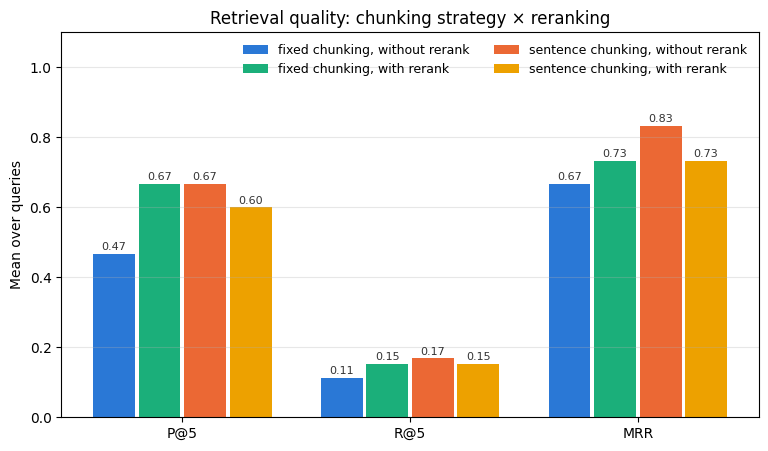

54338 bytes


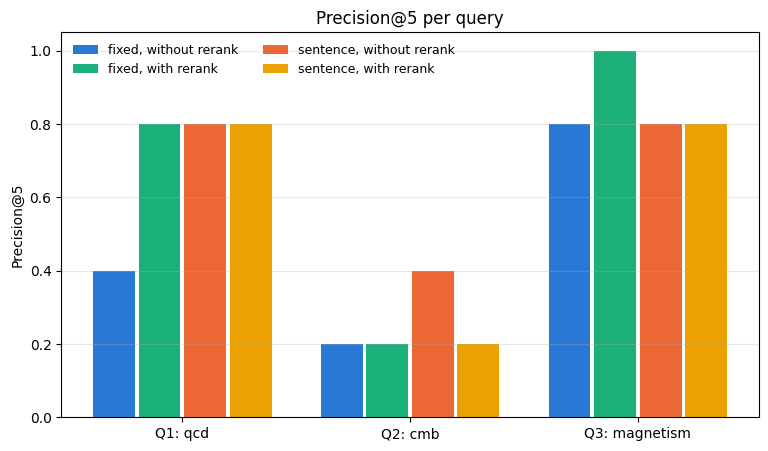

INFO:/content/data266-5937/hw10:Saved metrics_chunking_reranking.png and precision_at5_per_query.png


40585 bytes
[main 1852517] hw10: comparison figures for chunking and reranking
 3 files changed, 1 insertion(+)
 create mode 100644 hw10/metrics_chunking_reranking.png
 create mode 100644 hw10/precision_at5_per_query.png
 


In [16]:
configs = [("fixed", "without", C_BLUE), ("fixed", "with", C_AQUA),
           ("sentence", "without", C_ORANGE), ("sentence", "with", C_YELLOW)]
metrics = ["P@5", "R@5", "MRR"]
x = np.arange(len(metrics)); w = 0.2

plt.figure(figsize=(9, 5))
for i, (s, r, col) in enumerate(configs):
    vals = summary[(summary.strategy == s) & (summary.reranking == r)][metrics].values[0]
    bars = plt.bar(x + (i - 1.5) * w, vals, w * 0.92, color=col, label=f"{s} chunking, {r} rerank")
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8, color="#333")
plt.xticks(x, metrics); plt.ylim(0, 1.1); plt.ylabel("Mean over queries")
plt.title("Retrieval quality: chunking strategy × reranking")
plt.legend(frameon=False, fontsize=9, ncol=2); plt.grid(axis="y", alpha=0.3)
plt.savefig(f"{HW_PATH}/metrics_chunking_reranking.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
print(os.path.getsize(f"{HW_PATH}/metrics_chunking_reranking.png"), "bytes")

plt.figure(figsize=(9, 5))
qids = [q["qid"] for q in QUERIES]; x = np.arange(len(qids))
for i, (s, r, col) in enumerate(configs):
    vals = [eval_df[(eval_df["query"] == q) & (eval_df.strategy == s) & (eval_df.reranking == r)]["P@5"].values[0] for q in qids]
    plt.bar(x + (i - 1.5) * w, vals, w * 0.92, color=col, label=f"{s}, {r} rerank")
plt.xticks(x, [f"{q['qid']}: {q['id']}" for q in QUERIES]); plt.ylim(0, 1.05); plt.ylabel("Precision@5")
plt.title("Precision@5 per query"); plt.legend(frameon=False, fontsize=9, ncol=2); plt.grid(axis="y", alpha=0.3)
plt.savefig(f"{HW_PATH}/precision_at5_per_query.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
print(os.path.getsize(f"{HW_PATH}/precision_at5_per_query.png"), "bytes")

logger.info("Saved metrics_chunking_reranking.png and precision_at5_per_query.png")
git_commit_push(REPO_PATH, f"{HW}: comparison figures for chunking and reranking")

## Cell 17 — Conversational memory + multi-turn demo
**Mechanism (simple, rule-based query contextualisation):** the memory stores every turn (query + retrieved chunk ids).
When a new query looks like a follow-up — it contains a reference word (*it, they, those, these, that…*) or is very short — the retriever
searches with `previous user turns + current query` instead of the bare query. The reranker also scores with this contextualised query.

Turn 1 asks about the topic; turn 2 (*"…uncertainty or error in **those** measurements?"*) never names the topic, so without memory it retrieves
uncertainty discussions from *any* paper.

In [17]:
class ConversationMemory:
    FOLLOWUP_CUES = re.compile(r"\b(it|its|they|them|their|those|these|this|that|such|same|above|previous|former|latter)\b")

    def __init__(self, max_turns=2):
        self.turns, self.max_turns = [], max_turns

    def is_followup(self, query):
        return bool(self.turns) and (bool(self.FOLLOWUP_CUES.search(query.lower())) or len(query.split()) < 6)

    def contextualize(self, query):
        if not self.is_followup(query):
            return query
        history = " ".join(t["query"] for t in self.turns[-self.max_turns:])
        return f"{history} {query}"

    def add(self, query, search_query, results):
        self.turns.append({"query": query, "search_query": search_query,
                           "chunk_ids": [r["chunk_id"] for r in results[:5]]})

    def clear(self):
        self.turns = []

def chat(turn_queries, strategy, rerank, use_memory):
    mem, outputs = ConversationMemory(), []
    for q in turn_queries:
        sq = mem.contextualize(q) if use_memory else q
        res = search(sq, strategy, rerank=rerank)
        mem.add(q, sq, res)
        outputs.append({"query": q, "search_query": sq, "results": res})
    return outputs

TURNS = [CONV_TOPIC["query"], FOLLOWUP_QUERY]
RUBRICS = [CONV_TOPIC, followup_rubric(CONV_TOPIC)]
print("Turn 1:", TURNS[0]); print("Turn 2:", TURNS[1])

MEM_RUNS = {}
for n in STRATEGIES:
    for rr in [False, True]:
        for um in [False, True]:
            MEM_RUNS[(n, rr, um)] = chat(TURNS, n, rr, um)

for um in [False, True]:   # show the best-practice config (sentence chunks + rerank) with and without memory
    out = MEM_RUNS[("sentence", True, um)]
    print(f"\n################ memory = {um} ################")
    for t, (o, rub) in enumerate(zip(out, RUBRICS), 1):
        print(f"Turn {t} search query -> '{o['search_query']}'")
        show(o["results"], rub, title=f"turn {t} | sentence | rerank | memory={um}")

logger.info(f"Conversational memory demo on topic={conv_id}; turn2='{FOLLOWUP_QUERY}'")
git_commit_push(REPO_PATH, f"{HW}: conversational memory + multi-turn demo")

Turn 1: How are extrasolar planets detected?
Turn 2: What are the main sources of uncertainty or error in those measurements?


INFO:/content/data266-5937/hw10:Conversational memory demo on topic=exoplanet; turn2='What are the main sources of uncertainty or error in those measurements?'



################ memory = False ################
Turn 1 search query -> 'How are extrasolar planets detected?'

=== turn 1 | sentence | rerank | memory=False ===
 1. [REL] doc   9 sentence-d9-c0 (dense rank 2, ce=3.67)
    one surprising result that has come out of the more than 200 extrasolar planet discoveries to date is the wide range of eccentricities observed. unlike our own solar system, many of the extrasolar planets which are not t...
 2. [ - ] doc   9 sentence-d9-c26 (dense rank 1, ce=3.62)
    in contrast, the mean rms for the remaining three systems was. additional factors such as a paucity of data (hd 37605) and short time baselines (hd 80606, hd 89744) made the determination of useful companion limits chall...
 3. [ - ] doc   9 sentence-d9-c14 (dense rank 11, ce=1.12)
    the best fit is obtained by including an acceleration of yr, indicating a distant orbiting body. such a finding would lend support to the hypothesis that very eccentric single - planet systems originate 

## Cell 18 — (Optional) generate answers from the retrieved chunks
Closes the RAG loop with a small local generator (`google/flan-t5-base`, no API key). Not part of the metrics — it just shows
what the turn-2 answer looks like with vs. without memory. Skip if you're short on time.

In [18]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
gen_tok = AutoTokenizer.from_pretrained("google/flan-t5-base")
gen_model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(device)

def answer(question, results, history=""):
    ctx = "\n".join(r["text"] for r in results[:3])
    prompt = (f"Conversation so far: {history}\n" if history else "") + \
             f"Answer the question using only the context.\nQuestion: {question}\nContext: {ctx}\nAnswer:"
    ids = gen_tok(prompt, return_tensors="pt", truncation=True, max_length=512).to(device)
    out = gen_model.generate(**ids, max_new_tokens=80)
    return gen_tok.decode(out[0], skip_special_tokens=True)

for um in [False, True]:
    o = MEM_RUNS[("sentence", True, um)]
    hist = TURNS[0] if um else ""
    print(f"memory={um}\n  Turn 1 answer: {answer(TURNS[0], o[0]['results'])}"
          f"\n  Turn 2 answer: {answer(TURNS[1], o[1]['results'], hist)}\n")
logger.info("Generated flan-t5-base answers for turn 1/2 with and without memory")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (4 outputs left out)

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

memory=False
  Turn 1 answer: current surveys
  Turn 2 answer: tag bias, tracking efficiency, identification efficiency, and fsr



INFO:/content/data266-5937/hw10:Generated flan-t5-base answers for turn 1/2 with and without memory


memory=True
  Turn 1 answer: current surveys
  Turn 2 answer: a paucity of data (hd 37605) and short time baselines (hd 80606, hd 89744)



## Cell 19 — Evaluate memory vs. no memory + chart

,turn,strategy,reranking,memory,n_relevant,P@5,R@5,P@10,R@10,MRR
1,2,fixed,without,without,17,0.0,0.000,0.0,0.000,0.0
3,2,fixed,without,with,17,0.8,0.235,0.6,0.353,1.0
5,2,fixed,with,without,17,0.0,0.000,0.0,0.000,0.0
7,2,fixed,with,with,17,0.8,0.235,0.7,0.412,1.0
9,2,sentence,without,without,14,0.0,0.000,0.0,0.000,0.0
11,2,sentence,without,with,14,0.4,0.143,0.5,0.357,1.0
13,2,sentence,with,without,14,0.0,0.000,0.0,0.000,0.0
15,2,sentence,with,with,14,0.8,0.286,0.8,0.571,1.0


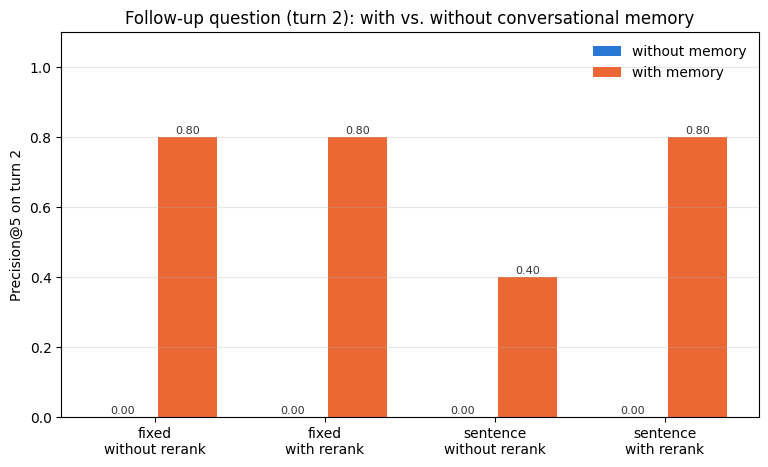

INFO:/content/data266-5937/hw10:Memory eval turn2: fixed/without/without: P@5=0.00; fixed/without/with: P@5=0.80; fixed/with/without: P@5=0.00; fixed/with/with: P@5=0.80; sentence/without/without: P@5=0.00; sentence/without/with: P@5=0.40; sentence/with/without: P@5=0.00; sentence/with/with: P@5=0.80


43528 bytes
[main c68b954] hw10: evaluate conversational memory, eval_memory.csv + figure
 3 files changed, 19 insertions(+)
 create mode 100644 hw10/eval_memory.csv
 create mode 100644 hw10/memory_comparison.png
 


In [19]:
mrows = []
for (n, rr, um), out in MEM_RUNS.items():
    for t, (o, rub) in enumerate(zip(out, RUBRICS), 1):
        rel = relevant_set(f"CONV_T{t}", rub, n)
        mrows.append({"turn": t, "strategy": n, "reranking": "with" if rr else "without",
                      "memory": "with" if um else "without", "search_query": o["search_query"],
                      "n_relevant": len(rel), **evaluate(o["results"], rel)})
mem_df = pd.DataFrame(mrows)
mem_df.to_csv(f"{HW_PATH}/eval_memory.csv", index=False)
mem_t2 = mem_df[mem_df.turn == 2].drop(columns=["search_query"]).round(3)
display(mem_t2)

plt.figure(figsize=(9, 5))
cfgs = [(n, r) for n in STRATEGIES for r in ["without", "with"]]
x = np.arange(len(cfgs)); w = 0.38
for i, (um, col) in enumerate([("without", C_BLUE), ("with", C_ORANGE)]):
    vals = [mem_t2[(mem_t2.strategy == n) & (mem_t2.reranking == r) & (mem_t2.memory == um)]["P@5"].values[0] for n, r in cfgs]
    bars = plt.bar(x + (i - 0.5) * w, vals, w * 0.92, color=col, label=f"{um} memory")
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8, color="#333")
plt.xticks(x, [f"{n}\n{r} rerank" for n, r in cfgs]); plt.ylim(0, 1.1); plt.ylabel("Precision@5 on turn 2")
plt.title("Follow-up question (turn 2): with vs. without conversational memory")
plt.legend(frameon=False); plt.grid(axis="y", alpha=0.3)
plt.savefig(f"{HW_PATH}/memory_comparison.png", bbox_inches="tight", dpi=150)
plt.show(); plt.close()
print(os.path.getsize(f"{HW_PATH}/memory_comparison.png"), "bytes")

logger.info("Memory eval turn2: " + "; ".join(f"{r['strategy']}/{r['reranking']}/{r['memory']}: P@5={r['P@5']:.2f}" for _, r in mem_t2.iterrows()))
git_commit_push(REPO_PATH, f"{HW}: evaluate conversational memory, eval_memory.csv + figure")

In [21]:
new_discussion = """## Discussion

**Reranking (mixed result).** Reranking helped fixed chunks (P@5 0.467 → 0.667, MRR 0.667 → 0.733) but hurt sentence chunks
(P@5 0.667 → 0.600, MRR 0.833 → 0.733). The largest drop was Q2 (CMB), where MRR fell from 1.0 to 0.2 in both strategies, and turn 1 of
the conversation, where P@5 fell from 0.8 to 0.4 (fixed) and 0.8 to 0.2 (sentence). Likely reasons: (1) the cross-encoder was trained
on MS MARCO web search, not lower-cased arXiv text with the math stripped out, so its sense of "relevant" differs from ours;
(2) our keyword rubric can mark a chunk not relevant even when it answers the question in different words, so some "drops" may be
rubric false negatives. Reranking only re-orders the top 30 dense candidates, so it can't recover anything the dense step missed.

**Chunking.** Without reranking, sentence-aware chunks beat fixed windows (P@5 +0.20, MRR +0.17). Fixed windows cut 92% of chunks
mid-sentence and can join the end of one section with the start of the next, which blurs the embedding. With reranking the two are
roughly tied (P@5 −0.067, which is one chunk in one query), because the cross-encoder partly makes up for messy boundaries in fixed
chunks. Recall isn't directly comparable across strategies because each collection has a different number of relevant chunks.

**Conversational memory (clearest effect).** The follow-up "...uncertainty or error in those measurements?" never names the topic.
Without memory, P@5 = 0 and MRR = 0 in all four configurations: it found uncertainty passages from unrelated papers. Adding the
previous question ("How are extrasolar planets detected?") raised turn-2 P@5 to 0.4–0.8 and MRR to 1.0 in every configuration
(mean P@5 +0.70). Turn-1 rows are identical with and without memory, as expected, since memory only rewrites follow-ups.
Limits: the follow-up trigger is a word list, so it would misfire on a new question containing "this" or "that", and the
query keeps growing as the conversation continues (history is capped at 2 turns). An LLM query rewriter would be the next step.

**Best configuration.** Fixed + reranking and sentence without reranking tie on P@5 (0.667); sentence without reranking wins on
MRR (0.833 vs 0.733) and R@10 (0.295 vs 0.213).

**Limitations.** Only 3 standalone queries and 1 conversation, so a difference of ±0.067 in mean P@5 is a single chunk and not
meaningful; only the ±0.2 differences and the memory effect are clear. Relevance is a keyword rubric: consistent across
configurations, but it rewards keyword overlap and misses paraphrases. Recall@K is low by design because topics have
11–32 relevant chunks and K ≤ 10.
"""

path = f"{HW_PATH}/METRICS.md"
txt = open(path).read()
with open(path, "w") as f:
    f.write(txt.split("## Discussion")[0] + new_discussion)
print(open(path).read()[-1500:])
logger.info("Rewrote METRICS.md Discussion to match actual results")
git_commit_push(REPO_PATH, f"{HW}: update METRICS.md discussion to reflect results")

INFO:/content/data266-5937/hw10:Rewrote METRICS.md Discussion to match actual results


ly makes up for messy boundaries in fixed
chunks. Recall isn't directly comparable across strategies because each collection has a different number of relevant chunks.

**Conversational memory (clearest effect).** The follow-up "...uncertainty or error in those measurements?" never names the topic.
Without memory, P@5 = 0 and MRR = 0 in all four configurations: it found uncertainty passages from unrelated papers. Adding the
previous question ("How are extrasolar planets detected?") raised turn-2 P@5 to 0.4–0.8 and MRR to 1.0 in every configuration
(mean P@5 +0.70). Turn-1 rows are identical with and without memory, as expected, since memory only rewrites follow-ups.
Limits: the follow-up trigger is a word list, so it would misfire on a new question containing "this" or "that", and the
query keeps growing as the conversation continues (history is capped at 2 turns). An LLM query rewriter would be the next step.

**Best configuration.** Fixed + reranking and sentence without reranking ti

## Cell 21 — AI_USE.md (guide §7 — fill in **your own words**, with a real pasted error)
Replace every `<...>`. Good real candidates: an error you actually hit while running this notebook (e.g. a dataset-loading error,
a Chroma batch-size error, a `NameError` after a reconnect) — paste the traceback text exactly.

In [23]:
ai_use_content = """# AI_USE.md

## 1. What I used AI for vs. wrote myself
- **AI :** Helped in the RAG pipelining code part: two chunking functions (fixed 150-word windows vs. sentence-aware), ChromaDB indexing and the conversational-memory class,
  Helped me infer the charts, and the evaluation code.
- **Me:** Performed data preprocessing, performed dense retrieval and cross-encoder reranking, set up the  workflow and parameters, reviewed the selected queries and retrieved chunks, compared the written findings against my actual result tables,
  and decided which conclusions the numbers actually support.

## 2. One specific wrong thing the AI produced
- I observed that:
- Fixed chunks improved: P@5 increased from 0.467 to 0.667.
- Sentence-aware chunks worsened: P@5 decreased from 0.667 to 0.600.
- Sentence-aware MRR also decreased from 0.833 to 0.733.
- MRR dropped from 1.0 to 0.2 under both strategies.
So there was a contention on whether the reranking really improved the retrieval.
## 3. How I found out it was wrong
- Answered above

## 4. What I changed and why the fix works
- The code was not the problem, but there were reasons on why this happened which was likely:
-The relevance rubric used keywords.
-Sentence-aware chunks may have lost context.
-The corpus and queries were small and specialized.
-Reranking used only the top 30 dense results
"""
if "<" in ai_use_content:
    print("REMINDER: placeholders <...> still present - fill them in and re-run this cell before final submission")
with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)
logger.info("Created AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")

INFO:/content/data266-5937/hw10:Created AI_USE.md


[main 39f92b9] hw10: add AI_USE.md
 2 files changed, 13 insertions(+), 4 deletions(-)
 


In [24]:
from google.colab import drive
drive.mount("/content/drive")

NB_NAME = "HW10_DATA266_5937.ipynb"
TARGET = "rag_reranking_chunking_memory.ipynb"
!cp "/content/drive/MyDrive/Colab Notebooks/{NB_NAME}" "{HW_PATH}/{TARGET}"
!ls -la {HW_PATH}

logger.info(f"Copied notebook with outputs into repo as {TARGET}")
git_commit_push(REPO_PATH, f"{HW}: add notebook with outputs")

Mounted at /content/drive
total 908
drwxr-xr-x  2 root root   4096 Nov  9 21:02 .
drwxr-xr-x 16 root root   4096 Nov  9 20:13 ..
-rw-r--r--  1 root root   1353 Nov  9 21:02 AI_USE.md
-rw-r--r--  1 root root  55203 Nov  9 20:16 chunk_length_distribution.png
-rw-r--r--  1 root root  16010 Nov  9 20:15 doc_overview.csv
-rw-r--r--  1 root root   2174 Nov  9 20:23 eval_memory.csv
-rw-r--r--  1 root root    747 Nov  9 20:21 eval_per_query.csv
-rw-r--r--  1 root root    308 Nov  9 20:21 eval_summary.csv
-rw-r--r--  1 root root  43528 Nov  9 20:23 memory_comparison.png
-rw-r--r--  1 root root  54338 Nov  9 20:22 metrics_chunking_reranking.png
-rw-r--r--  1 root root   9784 Nov  9 20:34 METRICS.md
-rw-r--r--  1 root root  40585 Nov  9 20:22 precision_at5_per_query.png
-rw-r--r--  1 root root   1576 Nov  9 20:20 query_coverage.csv
-rw-------  1 root root 619981 Nov  9 21:02 rag_reranking_chunking_memory.ipynb
-rw-r--r--  1 root root  41320 Nov  9 20:22 retrieval_results.csv
-rw-r--r--  1 root ro

INFO:/content/data266-5937/hw10:Copied notebook with outputs into repo as rag_reranking_chunking_memory.ipynb


[main 57aa4fc] hw10: add notebook with outputs
 2 files changed, 2 insertions(+)
 create mode 100644 hw10/rag_reranking_chunking_memory.ipynb
 


In [25]:
!cd {REPO_PATH} && git log --oneline -15
!cd {REPO_PATH} && git status
!cat {HW_PATH}/RUN_LOG.txt
!head -60 {HW_PATH}/METRICS.md
!ls -la {HW_PATH}

57aa4fc (HEAD -> main, origin/main, origin/HEAD) hw10: add notebook with outputs
39f92b9 hw10: add AI_USE.md
da57bbd hw10: add AI_USE.md
fcaa2fa hw10: update METRICS.md discussion to reflect results
733f6c1 hw10: METRICS.md with comparisons and findings
c68b954 hw10: evaluate conversational memory, eval_memory.csv + figure
f900a99 hw10: conversational memory + multi-turn demo
1852517 hw10: comparison figures for chunking and reranking
d77876d hw10: evaluate P@K/R@K/MRR, eval_per_query.csv + eval_summary.csv
ad9ef61 hw10: retrieval with reranking
8c9913e hw10: baseline retrieval without reranking
d282742 hw10: define queries, relevance rubric, query_coverage.csv
01693b4 hw10: index both chunk sets in ChromaDB
4a83276 hw10: embed chunks with all-MiniLM-L6-v2
63d6324 hw10: chunk length distribution figure
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
2026-11-09 20:13:53,908 | === Session started for hw10 ===
2026-11-09 20:14:25,842 | P

In [26]:
git_tag_push(REPO_PATH, HW)
!cd {REPO_PATH} && git tag -l && git status

hw1
hw10
hw2
hw2-5
hw3
hw4
hw4-5
hw4-5-1
hw5
hw6
hw6-1
hw7
hw8
hw9
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
